In [2]:
import pandas as pd
df=pd.read_csv(r"C:\Users\user\Downloads\Student_Performance_Analysis.csv")
print(df.to_string())

    Student_ID  Gender  Age  Study_Hours  Attendance  Assignments  Previous_Score  Midterm_Score  Final_Score  Sleep_Hours  Internet_Hours Extracurricular            Department
0       STU001    Male   24          3.6        90.6         93.2            68.6           78.8         92.5          7.4             1.9             Yes          Data Science
1       STU002  Female   25          5.2        80.4         81.3            87.8           98.0         91.8          7.7             2.0             Yes          Data Science
2       STU003    Male   24          5.3        81.8         82.4            72.4           89.9        100.0          6.1             3.1              No            Networking
3       STU004    Male   18          3.5        72.0         72.6            93.1           87.8         98.3          4.0             4.2              No            Networking
4       STU005    Male   21          8.2        81.8         71.7            93.2           98.0        100.0      

In [7]:
# BASIC ANALYSIS
import numpy as np
# Average study hours 
Avg_Study_Hours=round(np.mean(df['Study_Hours']),2)
print(f'AVERAGE STUDY HOURS: ',Avg_Study_Hours)

# AVERAGE ATTENDACE
Avg_Attendace=round(np.mean(df['Attendance']),2)
print(f'AVERAGE ATTENDANCE: ',Avg_Attendace)

# AVERAGE FINAL SCORE
Avg_Score=round(np.mean(df['Final_Score']),2)
print(f'Average Score: ',Avg_Score)

# Highest Score
Highest_Score=np.max(df['Final_Score'])
print(f'Highest Score: ',Highest_Score)

# Lowest Score
Lowest_Score=np.min(df['Final_Score']) 
print(f'Lowest Score: ',Lowest_Score)
print('---------------------------------------------------------------------------------')
# Having an overview of the data
head=df.head()
print(head)
print('---------------------------------------------------------------------------------')
# Having information about the dataset
info=df.info()
print(info)
print('---------------------------------------------------------------------------------')
# Getting the shape of the dataset
shape=df.shape
print(shape)
print('---------------------------------------------------------------------------------')
# Description of the data
describe=df.describe()
print(describe)
print('---------------------------------------------------------------------------------')
# Finding the top 10 studdents
Top_Students=df.nlargest(10,'Final_Score')
print(Top_Students[['Student_ID','Department','Final_Score']])
print('---------------------------------------------------------------------------------')
# Finding bottom 10 students
Bottom_Students=df.nsmallest(10,'Final_Score')
print(Bottom_Students[['Student_ID','Department','Final_Score']])
print('---------------------------------------------------------------------------------')
# Finding how many students scored above 70
above70=df[df['Final_Score']>70].shape[0]
print(f'Scores Above 70: ',above70)
print('---------------------------------------------------------------------------------')
# Finding how many students scored below 50
below50=df[df['Final_Score']<=50].shape[0]
print(f'Scores Below 50: ',below50)

# Calculating the percentage of those who scored above 70
percentage=(above70/len(df['Student_ID']))*100
print(f'Percentage: ',percentage, '%')

# Average score of students who studied more than 6 hours
average_Score=round(df.loc[df['Study_Hours']>6,'Final_Score'].mean(),2)
print(average_Score)



AVERAGE STUDY HOURS:  4.92
AVERAGE ATTENDANCE:  81.3
Average Score:  95.08
Highest Score:  100.0
Lowest Score:  67.6
---------------------------------------------------------------------------------
  Student_ID  Gender  Age  Study_Hours  Attendance  Assignments  \
0     STU001    Male   24          3.6        90.6         93.2   
1     STU002  Female   25          5.2        80.4         81.3   
2     STU003    Male   24          5.3        81.8         82.4   
3     STU004    Male   18          3.5        72.0         72.6   
4     STU005    Male   21          8.2        81.8         71.7   

   Previous_Score  Midterm_Score  Final_Score  Sleep_Hours  Internet_Hours  \
0            68.6           78.8         92.5          7.4             1.9   
1            87.8           98.0         91.8          7.7             2.0   
2            72.4           89.9        100.0          6.1             3.1   
3            93.1           87.8         98.3          4.0             4.2   
4       

0.54


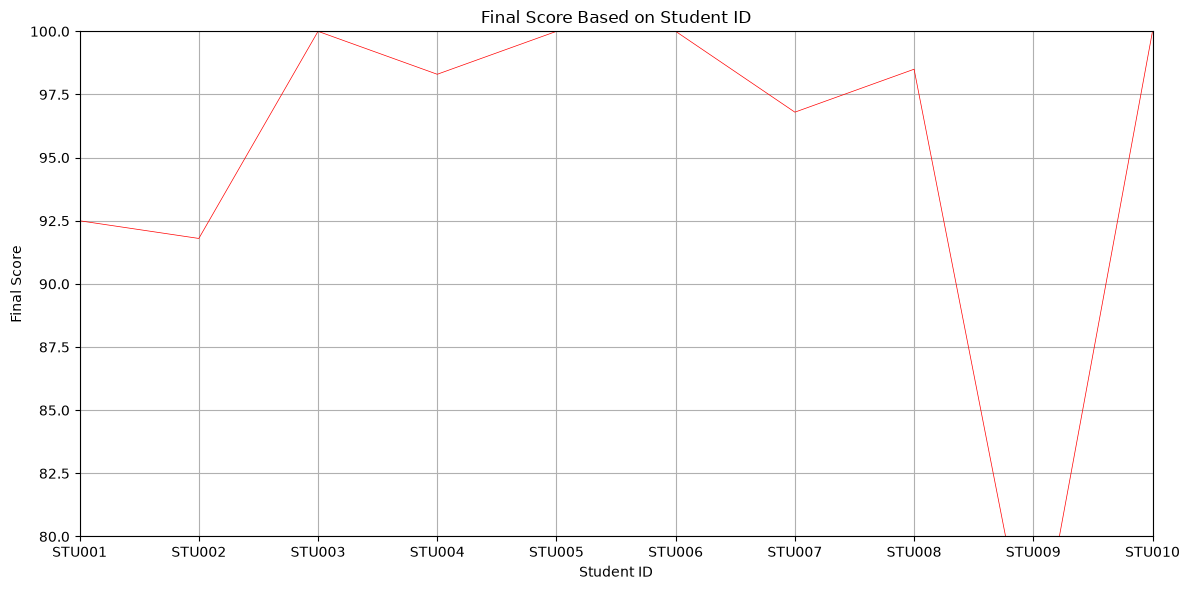

In [18]:
# DATA VISUALIZATIONS
import matplotlib.pyplot as plt
import numpy as np

# Calculating the correlation
correlation=np.corrcoef(df['Study_Hours'], df['Final_Score'])[0,1]
print(round(correlation,2))

# CREATING A LINE CHART
fig,ax=plt.subplots(figsize=(12,6))

ax.plot(df['Student_ID'],df['Final_Score'],
        lw=0.5,
        color='r')
ax.set_title('Final Score Based on Student ID')
ax.set_xlabel('Student ID')
ax.set_ylabel('Final Score')
ax.set_ylim(80,100)
ax.set_xlim('STU001','STU010')
ax.grid()
plt.tight_layout()
plt.show()

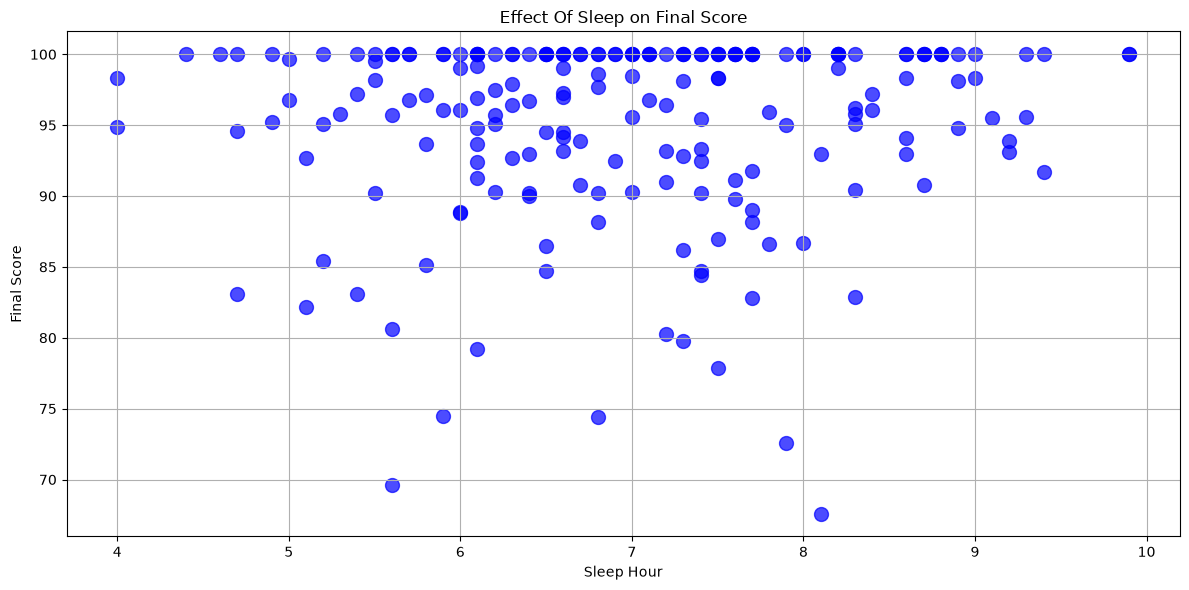

In [22]:
# PLORTTING A SCATTER CHART
import matplotlib.pyplot as plt

fig,ax=plt.subplots(figsize=(12,6))
ax.scatter(df['Sleep_Hours'],df['Final_Score'],
           s=100,alpha=0.7,color='b')
ax.set_title('Effect Of Sleep on Final Score')
ax.set_xlabel('Sleep Hour')
ax.set_ylabel('Final Score')
ax.grid()
plt.savefig('Effect_of_sleep.png')
plt.tight_layout()
plt.show()

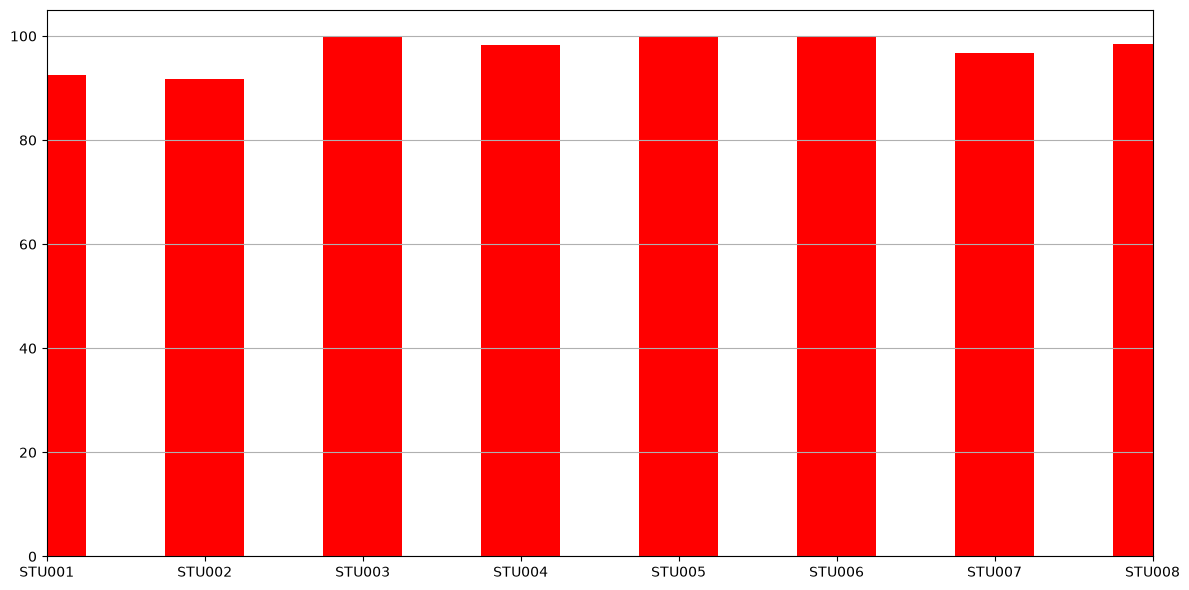

In [ ]:
# Creating a bar chart student id againist final score
import matplotlib.pyplot as plt

fig,ax=plt.subplots(figsize=(12,6))

ax.bar(df['Student_ID'],df['Final_Score'],width=0.5,color='r')
ax.set_xlim('STU001','STU008')
ax.grid(axis='y')
plt.tight_layout()
plt.show()

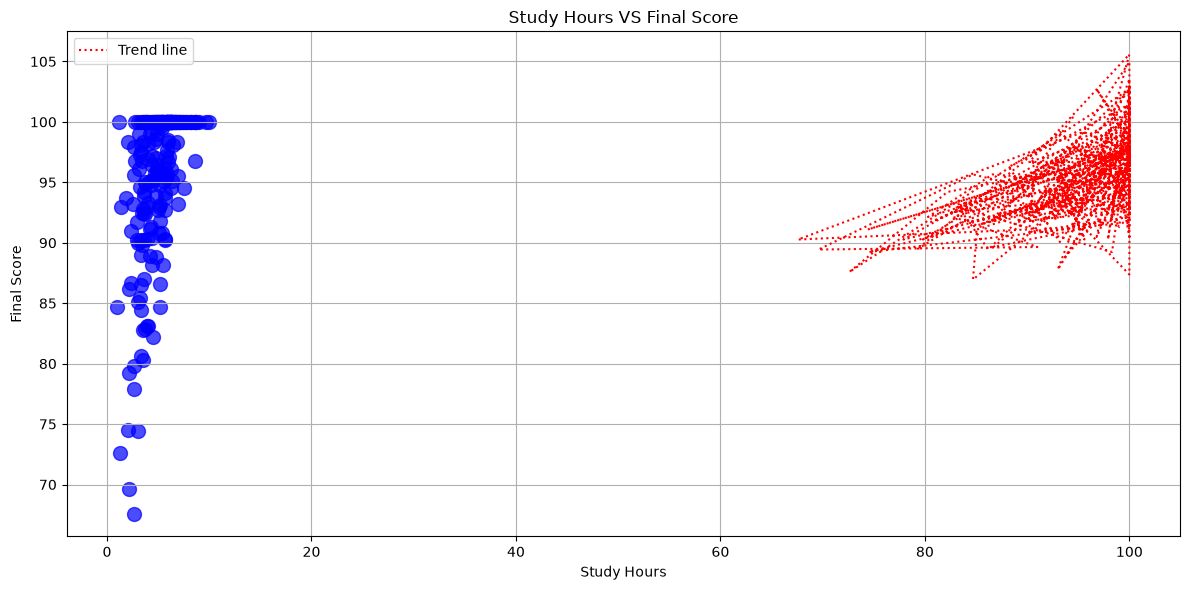

In [7]:
# Drawing a trend line by calculating the correlation
import matplotlib.pyplot as plt
import numpy as np

fig,ax=plt.subplots(figsize=(12,6))

ax.scatter(df['Study_Hours'],
           df['Final_Score'],
           s=100,
           alpha=0.7,
           color='b')

# Calculate the trend line points
slope,intercept=np.polyfit(df['Study_Hours'],df['Final_Score'],1)

trend=slope *np.array(df['Study_Hours'])+intercept

# Plot the line
ax.plot(df['Final_Score'],trend,
        ls=':',
        c='r',
        label='Trend line')
ax.set_title('Study Hours VS Final Score')
ax.set_xlabel('Study Hours')
ax.set_ylabel('Final Score')

ax.grid()
ax.legend()
plt.tight_layout()
plt.show()
